# Metrics To Evaluate Machine Learning Algorithms

The metrics that you choose to evaluate your machine learning algorithms with are very important. Choice of metrics influences how the performance of machine learning algorithms is measured and compared. They influence how you weight the importance of different characteristics in the results and ultimately the algorithm to choose.

First, we test the regression metrics using the housing datatest. Then, we test the classification metrics using the Pima Indians diabetes dataset.



## Regression Metrics

For regression metrics, we use the Boston House Price dataset

**The Mean Absolute Error** (or MAE) is the average of the absolute differences between predictions and actual values. It gives an idea of how wrong the predictions were. The example below demonstrates calculating mean absolute error on the Boston house price dataset.

In [1]:
# Cross Validation Regression MAE
import pandas
from sklearn import model_selection
from sklearn.linear_model import LinearRegression
url = "housing.data"
names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']
dataframe = pandas.read_csv(url, sep=r'\s+', names=names)
array = dataframe.values
X = array[:,0:13]
Y = array[:,13]
seed = 7
kfold = model_selection.KFold(n_splits=10,shuffle=True, random_state=seed)
model = LinearRegression()
scoring = 'neg_mean_absolute_error'
results = model_selection.cross_val_score(model, X, Y, cv=kfold, scoring=scoring)
print("MAE: %.3f (%.3f)" % (results.mean(), results.std()))

MAE: -3.387 (0.667)


A value of 0 indicates no error or perfect predictions.

**The Mean Squared Error** (or MSE) is much like the mean absolute error in that it provides a gross idea of the magnitude of error. The example below provides a demonstration of calculating mean squared error.

In [2]:
# Cross Validation Regression MSE
import pandas
from sklearn import model_selection
from sklearn.linear_model import LinearRegression
url = "housing.data"
names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']
dataframe = pandas.read_csv(url, sep=r'\s+', names=names)
array = dataframe.values
X = array[:,0:13]
Y = array[:,13]
seed = 7
kfold = model_selection.KFold(n_splits=10,shuffle=True, random_state=seed)
model = LinearRegression()
scoring = 'neg_mean_squared_error'
results = model_selection.cross_val_score(model, X, Y, cv=kfold, scoring=scoring)
print("MSE: %.3f (%.3f)" % (results.mean(), results.std()))

MSE: -23.747 (11.143)


In [3]:
import numpy as np
rmse_scores = np.sqrt(np.abs(results))          # |neg_MSE| puis racine, fold par fold
print("RMSE (racine de |MSE moyen|) : %.3f" % np.sqrt(np.abs(results.mean())))
print("RMSE moyen par fold          : %.3f (%.3f)" % (rmse_scores.mean(), rmse_scores.std()))

RMSE (racine de |MSE moyen|) : 4.873
RMSE moyen par fold          : 4.735 (1.153)


 Remember to take the absolute value before taking the square root to calculate the RMSE. Calculate it.
 
**The R^2 (or R Squared)** metric provides an indication of the goodness of fit of a set of predictions to the actual values. In statistical literature, this measure is called the coefficient of determination. The example below provides a demonstration of calculating the mean R^2 for a set of predictions.

In [4]:
# Cross Validation Regression R^2
import pandas
from sklearn import model_selection
from sklearn.linear_model import LinearRegression
url = "housing.data"
names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']
dataframe = pandas.read_csv(url, sep=r'\s+', names=names)
array = dataframe.values
X = array[:,0:13]
Y = array[:,13]
seed = 7
kfold = model_selection.KFold(n_splits=10,shuffle=True, random_state=seed)
model = LinearRegression()
scoring = 'r2'
results = model_selection.cross_val_score(model, X, Y, cv=kfold, scoring=scoring)
print("R^2: %.3f (%.3f)" % (results.mean(), results.std()))

R^2: 0.718 (0.099)


## Classification Metrics

**Classification accuracy** is the number of correct predictions made as a ratio of all predictions made. Below is an example of calculating classification accuracy.

In [5]:
# Cross Validation Classification Accuracy
import pandas
from sklearn import model_selection
from sklearn.neighbors import KNeighborsClassifier
url = "pima-indians-diabetes.data.csv"
names = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class']
dataframe = pandas.read_csv(url, names=names)
array = dataframe.values
X = array[:,0:8]
Y = array[:,8]
seed = 7
kfold = model_selection.KFold(n_splits=10,shuffle=True, random_state=seed)
model= KNeighborsClassifier(n_neighbors=10)
scoring = 'accuracy'
results = model_selection.cross_val_score(model, X, Y, cv=kfold, scoring=scoring)
print("Accuracy: %.3f +/- (%.3f)" % (results.mean(), results.std()))

Accuracy: 0.744 +/- (0.049)


Change the number of folds and see what happens ? ....

In [6]:
for n in [3, 5, 10, 20, 50]:
    kf = model_selection.KFold(n_splits=n, shuffle=True, random_state=seed)
    r = model_selection.cross_val_score(KNeighborsClassifier(n_neighbors=10), X, Y, cv=kf, scoring="accuracy")
    print(f"{n:>3} folds -> accuracy = {r.mean():.3f} (+/- {r.std():.3f})")

  3 folds -> accuracy = 0.755 (+/- 0.005)


  5 folds -> accuracy = 0.740 (+/- 0.033)
 10 folds -> accuracy = 0.744 (+/- 0.049)


 20 folds -> accuracy = 0.747 (+/- 0.070)


 50 folds -> accuracy = 0.744 (+/- 0.123)


**Remarque** : l'accuracy moyenne reste stable (≈ 0.74–0.755) quel que soit le nombre de plis, mais l'**écart-type augmente** avec le nombre de plis (0.005 → 0.049 → 0.123), car chaque pli de test devient plus petit (donc plus bruité). Plus de plis = estimation moins biaisée de la performance, mais plus coûteuse en calcul et avec plus de variance par pli. K=10 est un bon compromis classique.

### ROC Curve
Area Under **ROC Curve** (or ROC AUC for short) is a performance metric for binary classification problems.The example below provides a demonstration of calculating AUC. The AUC represents a model’s ability to discriminate between positive and negative classes. An area of 1.0 represents a model that made all predictions perfectly. An area of 0.5 represents a model as good as random.



AUC: 0.783  (0.059) 


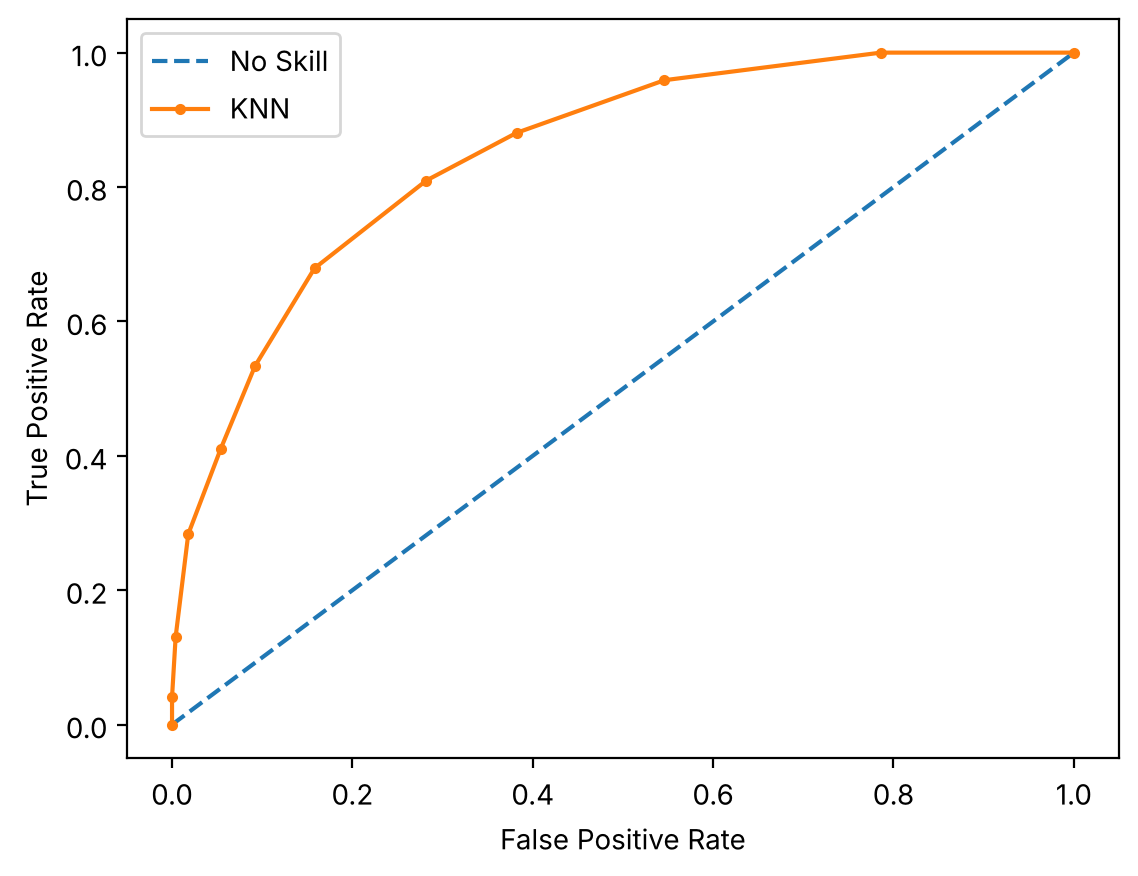

In [7]:
# Cross Validation Classification ROC AUC
from matplotlib import pyplot
from sklearn.metrics import roc_curve

url = "pima-indians-diabetes.data.csv"
names = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class']
dataframe = pandas.read_csv(url, names=names)
array = dataframe.values
X = array[:,0:8]
Y = array[:,8]
seed = 7
kfold = model_selection.KFold(n_splits=10,shuffle=True, random_state=seed)
model= KNeighborsClassifier(n_neighbors=10)
scoring = 'roc_auc'
results = model_selection.cross_val_score(model, X, Y, cv=kfold, scoring=scoring)
print("AUC: %.3f " % results.mean(), "(%.3f) " % results.std())

model.fit(X, Y)
# predict probabilities
yhat = model.predict_proba(X)
# retrieve just the probabilities for the positive class
pos_probs = yhat[:, 1]
# plot no skill roc curve
pyplot.plot([0, 1], [0, 1], linestyle='--', label='No Skill')
# calculate roc curve for model
fpr, tpr, _ = roc_curve(Y, pos_probs)
# plot model roc curve
pyplot.plot(fpr, tpr, marker='.', label='KNN')
# axis labels
pyplot.xlabel('False Positive Rate')
pyplot.ylabel('True Positive Rate')
# show the legend
pyplot.legend()
# show the plot
pyplot.show()

What are your remarks ?

**Remarques**
- AUC (CV 10 plis) = **0.783** (± 0.059) : nettement supérieur à 0.5 (modèle aléatoire), le modèle discrimine raisonnablement les patients diabétiques, mais est loin de 1.0.
- La courbe tracée est calculée en **réentraînant et testant sur les mêmes données** (`model.fit(X, Y)` puis `predict_proba(X, ...)`) : elle est donc **optimiste** (biais d'évaluation sur les données d'entraînement). L'AUC obtenue en validation croisée (0.78) est plus fiable.
- Le KNN avec K=10 produit des probabilités par pas de 0.1 (proportion de voisins), d'où une courbe en escalier avec peu de seuils distincts.
- Matrice de confusion et rapport : 45 faux négatifs contre 19 faux positifs, rappel de la classe 1 = **0.51** seulement (precision 0.71) : le modèle manque près de la moitié des diabétiques, ce qui est grave en contexte médical ; l'accuracy globale (0.75) masque ce déséquilibre (65 % de non-diabétiques).

### Confusion Matrix

**The confusion matrix** is a handy presentation of the accuracy of a model with two or more classes. Below is an example of calculating a confusion matrix for a set of prediction by a model on a test set.

In [8]:
# Cross Validation Classification Confusion Matrix
from sklearn.metrics import confusion_matrix
url = "pima-indians-diabetes.data.csv"
names = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class']
dataframe = pandas.read_csv(url, names=names)
array = dataframe.values
X = array[:,0:8]
Y = array[:,8]
test_size = 0.33
seed = 7
X_train, X_test, Y_train, Y_test = model_selection.train_test_split(X, Y, test_size=test_size, random_state=seed)
model= KNeighborsClassifier(n_neighbors=10)
model.fit(X_train, Y_train)
predicted = model.predict(X_test)
matrix = confusion_matrix(Y_test, predicted)
print(matrix)

[[143  19]
 [ 45  47]]


Scikit-learn does provide a convenience report when working on classification problems to give you a quick idea of the accuracy of a model using a number of measures.

The *classification_report()* function displays the **precision**, **recall**, **f1-score** and **support** for each class. The example below demonstrates the report on the binary classification problem.

In [9]:
# Cross Validation Classification Report
from sklearn.metrics import classification_report
url = "pima-indians-diabetes.data.csv"
names = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class']
dataframe = pandas.read_csv(url, names=names)
array = dataframe.values
X = array[:,0:8]
Y = array[:,8]
test_size = 0.33
seed = 7
X_train, X_test, Y_train, Y_test = model_selection.train_test_split(X, Y, test_size=test_size, random_state=seed)
model= KNeighborsClassifier(n_neighbors=10)
model.fit(X_train, Y_train)
predicted = model.predict(X_test)
report = classification_report(Y_test, predicted)
print(report)

              precision    recall  f1-score   support

         0.0       0.76      0.88      0.82       162
         1.0       0.71      0.51      0.59        92

    accuracy                           0.75       254
   macro avg       0.74      0.70      0.71       254
weighted avg       0.74      0.75      0.74       254



## Activities

Using all the algorithms studied in class — *Polynomial Regression, Logistic Regression, Naive Bayes, Decision Trees, and KNN* — compare their performance to determine:

1. Which model gives the **best results for regression** and which gives the **best results for classification**?  
2. What are their **best parameters and hyperparameters** (using GridSearchCV or RandomizedSearchCV)?  
3. Present your results for both tasks in **two summary tables**:

**Classification Results**

| Model | Accuracy | Precision | Recall | F1-Score | Best Parameters |
|:------|:----------|:-----------|:--------|:----------|:----------------|

**Regression Results**

| Model | R² | MAE | MSE | RMSE | Best Parameters |
|:------|:----|:----|:----|:------|:----------------|

4. Based on your results, briefly explain:  
   - Which models perform best and why?  
   - What trade-offs (accuracy vs. complexity, interpretability, etc.) did you observe?  

## Solution des activités — comparaison des modèles

**Protocole** : découpage 80 % / 20 % (`random_state=7`) ; recherche d'hyperparamètres par `GridSearchCV` (CV 5 plis, sur le train uniquement) ; métriques calculées sur le jeu de test. Pour la classification, les variables sont standardisées (nécessaire pour KNN / régression logistique). Les modèles sont ceux du cours : *Régression polynomiale* (régression), *Régression logistique* et *Naive Bayes* (classification), *Arbres de décision* et *KNN* (les deux tâches).

In [10]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from sklearn.model_selection import GridSearchCV, train_test_split, StratifiedKFold, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression, Ridge, LinearRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             r2_score, mean_absolute_error, mean_squared_error)
pd.set_option("display.max_colwidth", 120)

# ---------- Classification : Pima Indians Diabetes
pima = pd.read_csv("pima-indians-diabetes.data.csv", names=['preg','plas','pres','skin','test','mass','pedi','age','class'])
Xc, yc = pima.iloc[:, :8].values, pima["class"].values
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.2, random_state=7, stratify=yc)

cls_models = {
    "Logistic Regression": (Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(max_iter=2000))]),
                            {"m__C": [0.01, 0.1, 1, 10, 100], "m__penalty": ["l2"]}),
    "Naive Bayes (Gaussian)": (Pipeline([("sc", StandardScaler()), ("m", GaussianNB())]),
                               {"m__var_smoothing": np.logspace(-11, -1, 11)}),
    "Decision Tree": (DecisionTreeClassifier(random_state=0),
                      {"max_depth": [2, 3, 4, 5, 6, 8, None], "min_samples_leaf": [1, 5, 10, 20], "criterion": ["gini", "entropy"]}),
    "KNN": (Pipeline([("sc", StandardScaler()), ("m", KNeighborsClassifier())]),
            {"m__n_neighbors": list(range(1, 41)), "m__weights": ["uniform", "distance"], "m__metric": ["euclidean", "manhattan"]}),
}
skf = StratifiedKFold(5, shuffle=True, random_state=7)
rows = []
for name, (est, grid) in cls_models.items():
    gs = GridSearchCV(est, grid, cv=skf, scoring="accuracy", n_jobs=-1).fit(Xc_tr, yc_tr)
    p = gs.predict(Xc_te)
    rows.append({"Model": name, "Accuracy": accuracy_score(yc_te, p), "Precision": precision_score(yc_te, p),
                 "Recall": recall_score(yc_te, p), "F1-Score": f1_score(yc_te, p), "CV acc (train)": gs.best_score_,
                 "Best Parameters": {k.replace("m__", ""): v for k, v in gs.best_params_.items()}})
cls_res = pd.DataFrame(rows).set_index("Model")
cls_res.round(3)

,Accuracy,Precision,Recall,F1-Score,CV acc (train),Best Parameters
Model,,,,,,
Logistic Regression,0.773,0.732,0.556,0.632,0.759,"{'C': 0.1, 'penalty': 'l2'}"
Naive Bayes (Gaussian),0.766,0.714,0.556,0.625,0.748,{'var_smoothing': 0.1}
Decision Tree,0.799,0.811,0.556,0.659,0.725,"{'criterion': 'gini', 'max_depth': 2, 'min_samples_leaf': 1}"
KNN,0.753,0.711,0.500,0.587,0.764,"{'metric': 'euclidean', 'n_neighbors': 26, 'weights': 'distance'}"


In [11]:
# ---------- Régression : Boston Housing
names = ['CRIM','ZN','INDUS','CHAS','NOX','RM','AGE','DIS','RAD','TAX','PTRATIO','B','LSTAT','MEDV']
house = pd.read_csv("housing.data", sep=r"\s+", names=names)
Xr, yr = house.iloc[:, :13].values, house["MEDV"].values
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=7)

reg_models = {
    "Linear Regression (référence)": (Pipeline([("sc", StandardScaler()), ("m", LinearRegression())]), {}),
    "Polynomial Regression": (Pipeline([("poly", PolynomialFeatures(include_bias=False)), ("sc", StandardScaler()), ("m", Ridge())]),
                              {"poly__degree": [1, 2, 3], "m__alpha": [0.01, 0.1, 1, 10, 100, 1000]}),
    "Decision Tree": (DecisionTreeRegressor(random_state=0),
                      {"max_depth": [3, 4, 5, 6, 8, 10, None], "min_samples_leaf": [1, 3, 5, 10, 20]}),
    "KNN": (Pipeline([("sc", StandardScaler()), ("m", KNeighborsRegressor())]),
            {"m__n_neighbors": list(range(1, 31)), "m__weights": ["uniform", "distance"], "m__metric": ["euclidean", "manhattan"]}),
}
kf = KFold(5, shuffle=True, random_state=7)
rows = []
for name, (est, grid) in reg_models.items():
    if grid:
        gs = GridSearchCV(est, grid, cv=kf, scoring="r2", n_jobs=-1).fit(Xr_tr, yr_tr); best, bp = gs.best_estimator_, gs.best_params_
    else:
        best, bp = est.fit(Xr_tr, yr_tr), {}
    p = best.predict(Xr_te); mse = mean_squared_error(yr_te, p)
    rows.append({"Model": name, "R²": r2_score(yr_te, p), "MAE": mean_absolute_error(yr_te, p), "MSE": mse,
                 "RMSE": np.sqrt(mse), "Best Parameters": {k.replace("m__", ""): v for k, v in bp.items()}})
reg_res = pd.DataFrame(rows).set_index("Model")
reg_res.round(3)

,R²,MAE,MSE,RMSE,Best Parameters
Model,,,,,
Linear Regression (référence),0.579,3.781,34.056,5.836,{}
Polynomial Regression,0.744,2.667,20.670,4.546,"{'alpha': 10, 'poly__degree': 3}"
Decision Tree,0.613,3.406,31.251,5.590,"{'max_depth': 10, 'min_samples_leaf': 10}"
KNN,0.753,2.940,19.994,4.471,"{'metric': 'manhattan', 'n_neighbors': 3, 'weights': 'distance'}"


In [12]:
print("=== Classification : meilleur modèle (F1) :", cls_res["F1-Score"].idxmax(), "| (Accuracy) :", cls_res["Accuracy"].idxmax())
print("=== Régression     : meilleur modèle (R²) :", reg_res["R²"].idxmax(), "| plus faible RMSE :", reg_res["RMSE"].idxmin())

=== Classification : meilleur modèle (F1) : Decision Tree | (Accuracy) : Decision Tree
=== Régression     : meilleur modèle (R²) : KNN | plus faible RMSE : KNN


## Synthèse et réponses

**Tableau 1 — Classification (Pima Indians Diabetes, jeu de test = 154 patients)**

| Model | Accuracy | Precision | Recall | F1-Score | Best Parameters |
|:--|:--|:--|:--|:--|:--|
| Logistic Regression | 0.773 | 0.732 | 0.556 | 0.632 | C=0.1, penalty=l2 |
| Naive Bayes (Gaussian) | 0.766 | 0.714 | 0.556 | 0.625 | var_smoothing=0.1 |
| **Decision Tree** | **0.799** | **0.811** | 0.556 | **0.659** | criterion=gini, max_depth=2, min_samples_leaf=1 |
| KNN | 0.753 | 0.711 | 0.500 | 0.587 | n_neighbors=26, weights=distance, metric=euclidean |

**Tableau 2 — Régression (Boston Housing, jeu de test = 102 maisons)**

| Model | R² | MAE | MSE | RMSE | Best Parameters |
|:--|:--|:--|:--|:--|:--|
| Linear Regression (référence) | 0.579 | 3.781 | 34.056 | 5.836 | — |
| Polynomial Regression (Ridge) | 0.744 | 2.667 | 20.670 | 4.546 | degree=3, alpha=10 |
| Decision Tree | 0.613 | 3.406 | 31.251 | 5.590 | max_depth=10, min_samples_leaf=10 |
| **KNN** | **0.753** | 2.940 | **19.994** | **4.471** | n_neighbors=3, weights=distance, metric=manhattan |

*(Logistic Regression et Naive Bayes sont des modèles de classification : ils ne s'appliquent pas à la régression. La régression polynomiale est un modèle de régression : elle n'est pas utilisée pour la classification.)*

**1. Meilleurs modèles**
- **Régression : KNN** (R² 0.753, RMSE 4.47) **et la régression polynomiale** (R² 0.744, RMSE 4.55, meilleure MAE : 2.67) sont pratiquement à égalité ; les deux dépassent nettement la régression linéaire (R² 0.58) → la relation entre variables et prix est **non linéaire**.
- **Classification : Decision Tree** (accuracy 0.80, F1 0.66) sur le test, mais l'écart avec la régression logistique (0.77) et Naive Bayes (0.77) est faible. Attention : en validation croisée sur le train (colonne « CV acc »), le **KNN (0.764)** et la **régression logistique (0.759)** sont devant l'arbre (0.725) : l'avantage de l'arbre sur le test peut être dû au hasard du découpage, et les différences (≈ 2-4 points sur 154 patients) ne sont pas significatives. La régression logistique est un choix plus sûr et stable.

**2. Meilleurs hyperparamètres** : voir les colonnes *Best Parameters* (GridSearchCV, CV 5 plis sur le train). Ex. : arbre peu profond (profondeur 2) pour Pima = fort élagage contre le sur-apprentissage ; KNN régression avec K=3 pondéré par la distance ; polynôme de degré 3 régularisé (Ridge, alpha=10) pour contrôler l'explosion du nombre de variables.

**3. Compromis observés**
- **Interprétabilité** : régression logistique et arbre de décision (peu profond) sont lisibles/explicables (coefficients, règles) ; KNN et polynôme de degré 3 sont des boîtes plus opaques.
- **Complexité / sur-apprentissage** : le polynôme de degré 3 crée 559 variables à partir de 13 → il faut régulariser (Ridge). L'arbre non élagué sur-apprend ; KNN avec K trop petit aussi (K=3 en régression fonctionne ici car les données sont denses et la pondération par la distance aide).
- **Coût** : KNN est « paresseux » (rapide à entraîner, lent à prédire, sensible à l'échelle → standardisation obligatoire). Naive Bayes est le plus rapide et un bon modèle de base, mais son hypothèse d'indépendance des variables est irréaliste ici.
- **Classification déséquilibrée** : tous les modèles ont un **rappel faible (0.50-0.56)** pour la classe « diabétique » ; en santé, on préférerait un modèle avec un meilleur rappel (ajustement du seuil, `class_weight="balanced"`), même au prix d'une accuracy plus basse. L'accuracy seule ne suffit donc pas : il faut regarder précision, rappel, F1 et AUC.